[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/MFM/blob/main/notebooks/RO/capitol1_notebook_seminar.ipynb)

# Modelarea piețelor financiare — Seminarul 1: Fapte stilizate și randamente

*Notebook de seminar. Daniel Traian Pele, Antoaneta Amza — Academia de Studii Economice din București.*

- **Partea A**: verificarea numerică a celor unsprezece exerciții pe hîrtie (exerciții introductive A1, A3, A4, A8; derivări A2, A5–A7, A9–A11).
- **Partea B**: B1–B3, B5, B9, B11, B13 și B15 verifică faptele stilizate; B4, B6–B8, B10, B12 și B14 le testează cu inferență robustă la cozi groase și volatility clustering.
- **Partea C**: C1, critica unui răspuns Artificial Intelligence (AI); C2 și C3, întrebări deschise pentru proiectul în echipă.
- Problemele **[Rezolvat]** sînt rezolvate complet (cod și rezultat); problemele **[Propus]** au o celulă goală, pe care o completați dumneavoastră: rezolvările se discută la seminar.
- Fiecare problemă propusă are ca model o problemă rezolvată: A2 și A7 după A1; A6 și A10 după A4; A9 după A4 și A6; A11 după A5; B2 și B7 după B1; B5 după B1 și B3; B8 după A10, B3 și B6; B9 după B3; B10 după B4 și B9; B11 după B1 și B4; B12 după B4 și B6; B13 după A1 și B1; B14 după B1(d) și B13; B15 după A8; C1 după A3, B3 și B4.

> Rezolvările se discută la seminar.

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.tsa.stattools import acf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
import warnings
warnings.filterwarnings('ignore')
import sys
if 'google.colab' in sys.modules:
    !pip -q install arch
import statsmodels.api as sm

In [ ]:
# Chart style: transparent background, legend below the plot
plt.rcParams['figure.facecolor'] = 'none'
plt.rcParams['axes.facecolor'] = 'none'
plt.rcParams['savefig.facecolor'] = 'none'
plt.rcParams['savefig.transparent'] = True
plt.rcParams['axes.grid'] = False
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Helvetica', 'Arial', 'DejaVu Sans']
plt.rcParams['font.size'] = 9
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['axes.titlesize'] = 11
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.linewidth'] = 0.6
plt.rcParams['lines.linewidth'] = 1.1
plt.rcParams['legend.facecolor'] = 'none'
plt.rcParams['legend.framealpha'] = 0
plt.rcParams['legend.fontsize'] = 8

# Chart colours
MainBlue = '#1A3A6E'
IDAred   = '#CD0000'
Forest   = '#2E7D32'
Amber    = '#B5853F'
Orange   = '#E67E22'
Purple   = '#8E44AD'
Crimson  = '#DC3545'
Navy     = '#1F2A44'   # reference lines (no grey in charts)
BandBlue = '#C5D2E8'   # light MainBlue tint for confidence / reference bands
Gray, LightGray = Navy, BandBlue   # legacy names kept for importing scripts
Teal     = '#17A2B8'

ASSETS = ['sp500', 'bettr', 'btc', 'eurron', 'gold']
COLORS = {'sp500': MainBlue, 'bettr': IDAred, 'btc': Amber, 'eurron': Forest, 'gold': Purple}
PERIODS = {'sp500': 252, 'bettr': 252, 'btc': 365, 'eurron': 252, 'gold': 252}


def save_fig(name):
    """Save the figure as PDF and transparent PNG in the current folder."""
    plt.savefig(f'{name}.pdf', bbox_inches='tight', transparent=True)
    plt.savefig(f'{name}.png', bbox_inches='tight', transparent=True, dpi=180)
    plt.show()
    plt.close()
    print(f"   saved {name}")


def legend_outside_bottom(ax, ncol=2, y=-0.22):
    """Place the legend outside the plot, bottom centre."""
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, y), ncol=ncol, frameon=False)



import os
import tempfile
# graficele și tabelele merg în OUT_DIR (setat în celula Colab de la început), altfel într-un folder temporar
TABLE_DIR = globals().get('OUT_DIR', tempfile.gettempdir())


def save_fig(name):
    """Salvează figura în TABLE_DIR și o afișează."""
    plt.savefig(os.path.join(TABLE_DIR, name + '.png'), dpi=150, bbox_inches='tight', transparent=True)
    plt.show()
    plt.close()

In [ ]:
REPO_RAW = 'https://raw.githubusercontent.com/danpele/MFM/main/data/market/'
# local copy of the course data, if the notebook runs inside the repository
MARKET_DIR = next((os.path.join(d, 'data', 'market') for d in ('.', '..', '../..', '../../..')
                   if os.path.isdir(os.path.join(d, 'data', 'market'))), '')

SOURCES = {
    'sp500':  ('GSPC.INDX',    'close', '1990-01-01'),
    'bettr':  ('BETTR.INDX',   'close', '2014-09-01'),
    'btc':    ('BTC-USD.CC',   'close', '2014-09-17'),
    'eurron': ('REF:EUR',      'close', '2005-07-01'),   # from the introduction of the new leu (RON), 1 July 2005
    'gold':   ('XAUUSD.FOREX', 'close', '1990-01-01'),
}

LABELS = {'sp500': 'S&P 500', 'bettr': 'BET-TR (Romania)', 'btc': 'Bitcoin',
          'eurron': 'EUR/RON', 'gold': 'Gold'}

# OTC quotes (gold): partial Saturday/Sunday sessions break the Friday -> Monday return,
# so we keep weekdays only (the same convention as in Chapter 0)
WEEKDAYS_ONLY = {'gold'}

_CACHE = {}


def read_market(symbol):
    """Read the daily price table of one symbol (local copy or GitHub)."""
    fname = f'{symbol}.csv'
    path = os.path.join(MARKET_DIR, fname)
    src = path if os.path.exists(path) else REPO_RAW + fname
    df = pd.read_csv(src, parse_dates=['date']).set_index('date').sort_index()
    df.index.name = 'Date'
    return df


def read_reference_rate(currency='EUR', start='2005-07-01', end='2026-09-18'):
    """Official RON reference rate (BNR annual XML archives)."""
    key = (currency, start, end)
    if key in _CACHE:
        return _CACHE[key]
    import re
    import urllib.request
    rows = []
    for y in range(int(start[:4]), int(end[:4]) + 1):
        url = f'https://curs.bnr.ro/files/xml/years/nbrfxrates{y}.xml'
        xml = urllib.request.urlopen(urllib.request.Request(url, headers={'User-Agent': 'Mozilla'}),
                                     timeout=60).read().decode()
        for d, body in re.findall(r'<Cube date="([\d-]+)">(.*?)</Cube>', xml, re.S):
            m = re.search(rf'<Rate currency="{currency}">([\d.]+)</Rate>', body)
            if m:
                rows.append((d, float(m.group(1))))
    df = pd.DataFrame(rows, columns=['Date', 'Close']).drop_duplicates('Date').set_index('Date')
    df.index = pd.to_datetime(df.index)
    _CACHE[key] = df.sort_index().loc[start:end]
    return _CACHE[key]


def load_data(name='sp500'):
    """Daily OHLCV with columns Open/High/Low/Close/Volume (Close = the price used)."""
    symbol, col, start = SOURCES[name]
    if symbol.startswith('REF:'):
        return read_reference_rate(symbol.split(':')[1], start=start)
    d = read_market(symbol).loc[start:]
    if name in WEEKDAYS_ONLY:
        d = d[d.index.dayofweek < 5]
    out = pd.DataFrame({'Open': d['open'], 'High': d['high'], 'Low': d['low'],
                        'Close': d[col], 'Volume': d['volume']})
    return out[out['Close'] > 0].dropna(subset=['Close'])


def load_close(name):
    """Closing price, used in all charts."""
    return load_data(name)['Close'].dropna()


closes = {a: load_close(a) for a in ASSETS}
rets = {a: np.log(c).diff().dropna() for a, c in closes.items()}
# gold (weekdays only) is annualised with its actual number of observations per year
PERIODS['gold'] = len(rets['gold']) / ((closes['gold'].index[-1] - closes['gold'].index[0]).days / 365.25)
spx_ohlc = load_data('sp500')
for a in ASSETS:
    print(f'{LABELS[a]:18s}', rets[a].index[0].date(), '->', rets[a].index[-1].date(), len(rets[a]), 'obs')

S&P 500            1990-01-03 -> 2026-09-18 9245 obs
BET-TR (Romania)   2014-09-24 -> 2026-09-18 2992 obs
Bitcoin            2014-09-18 -> 2026-09-18 4384 obs
EUR/RON            2005-07-05 -> 2026-09-18 5352 obs
Gold               1990-01-03 -> 2026-09-18 9559 obs


In [ ]:
SEED = 42
HILL_FRACS_TAILS = np.round(np.arange(0.01, 0.1001, 0.0025), 4)
BLUE_CHIPS = ['TLV.RO', 'SNP.RO', 'BRD.RO', 'TGN.RO', 'FP.RO', 'SNG.RO', 'H2O.RO', 'SNN.RO', 'EL.RO', 'DIGI.RO', 'TEL.RO']


def hill_estimator(x, k):
    """alpha_hat(k) = [ (1/k) sum_{i=1..k} ln(X_(i) / X_(k+1)) ]^{-1}, X_(1) >= X_(2) >= ..."""
    x = np.sort(np.asarray(x)[np.asarray(x) > 0])[::-1]
    return 1.0 / np.mean(np.log(x[:k] / x[k]))

## Partea A — exerciții pe hîrtie (verificare numerică)

### A1. Randamente și anualizare, exercițiu introductiv [Rezolvat]

- Prețuri 100, 110, 99, 104,5 (fără dividend): calculați randamentele zilnice simple și logaritmice și comparați randamentele pe 3 zile cu sumele lor.
- Portofoliu 60% A ($R_A = +5\%$), 40% B ($R_B = -2\%$): calculați $R_p$, randamentul logaritmic ponderat și $\ln(1+R_p)$.
- Anualizați o medie zilnică de 0,04% și o volatilitate de 1,2% cu $P = 252$, și o volatilitate Bitcoin de 3,5% cu valoarea adecvată a lui $P$.
- Interpretare:
  - ce randament se agregă în timp?
  - care se agregă între active?

In [ ]:
# A1 agregare în timp și între active
P = np.array([100, 110, 99, 104.5])
R = P[1:] / P[:-1] - 1; r = np.log(P[1:] / P[:-1])
print('R =', R.round(4), ' r =', r.round(4))
print('simplu 3 zile:', round(P[-1] / P[0] - 1, 4), ' sum R:', round(R.sum(), 4), ' log 3 zile:', round(np.log(P[-1] / P[0]), 4), ' sum r:', round(r.sum(), 4))
Rp = 0.6 * 0.05 + 0.4 * (-0.02)
print('Rp =', Rp, ' log ponderat =', round(0.6 * np.log(1.05) + 0.4 * np.log(0.98), 5),
      ' log real =', round(np.log(1 + Rp), 5))
print('mu_ann =', 252 * 0.0004, ' sigma_ann =', round(np.sqrt(252) * 0.012, 4), ' BTC =', round(np.sqrt(365) * 0.035, 4))

R = [ 0.1    -0.1     0.0556]  r = [ 0.0953 -0.1054  0.0541]
simplu 3 zile: 0.045  sum R: 0.0556  log 3 zile: 0.044  sum r: 0.044
Rp = 0.022  log ponderat = 0.02119  log real = 0.02176
mu_ann = 0.1008  sigma_ann = 0.1905  BTC = 0.6687


### A2. Un reper pentru amplitudinea drawdown-ului [Propus]

**A2(a). Amplitudinea unui drawdown**

- **Model**: [A1](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-A1) \[Rezolvat\]; secțiunea [A2](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-A2a) din notebook

- **Întrebări**

  - care este cea mai mare pierdere față de un vîrf anterior?

  - cum se raportează aceasta la rata anuală de creștere?

- **Date de intrare**

  - valorile portofoliului la sfîrșit de an $V_0, \dots, V_5$ = 100, 120, 90, 110, 130, 117

  - Compound Annual Growth Rate (CAGR) pe 5 ani $(V_5/V_0)^{1/5} - 1 = 3{,}19\%$: rata anuală constantă care duce $V_0$ la $V_5$

- **Cerințe**: completați tabelul

  1.  Calculați vîrful $M_t = \max_{s \leq t} V_s$, cel mai mare $V_s$ din anii $s = 0, \dots, t$.

  2.  Calculați drawdown-ul $DD_t = V_t/M_t - 1 \leq 0$, pierderea relativă față de vîrf.

  3.  Determinați drawdown-ul maxim $MDD = \min_t DD_t$ și anul în care apare.

  4.  Calculați raportul Calmar CAGR$/|MDD|$, creșterea anuală pe unitatea de pierdere maximă.

| Anul   |   0 |   1 |   2 |   3 |   4 |   5 |
|:-------|----:|----:|----:|----:|----:|----:|
| $V_t$  | 100 | 120 |  90 | 110 | 130 | 117 |
| $M_t$  | 100 | 120 | ... | ... | ... | ... |
| $DD_t$ |  0% |  0% | ... | ... | ... | ... |

- **Interpretare**: de ce scăderea la 117 din anul 5 nu este drawdown-ul maxim?

**A2(b–f). Un reper pentru drawdown**

- **Model**: [A2(a)](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-A2a); secțiunea [A2](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-A2a) din notebook

- **Ipoteză**: logaritmul prețului este $X_t = \mu t + \sigma W_t$

  - $W_t$ este o mișcare browniană standard: creșteri independente, $W_t \sim N(0, t)$

  - $\mu$: drift-ul anual al logaritmului prețului; $\sigma$: volatilitatea anuală; $T$: orizontul, în ani

  - drawdown-ul maxim logaritmic $D = \max_{s \leq t \leq T}(X_s - X_t) = -\ln(1 + MDD)$: cea mai mare scădere a lui $X$ de la un vîrf $s$ la un moment ulterior $t$

  - pentru $\mu = 0$: $\mathbb{E}[D] = \sqrt{\pi/2}\,\sigma\sqrt{T}$ [Magdon-Ismail et al. (2004)](https://doi.org/10.1239/jap/1077134674), cu $\sqrt{\pi/2} = 1{,}2533$

- **Date de intrare**: aur spot, 1990--2026

  - $\sigma = 16{,}3\%$, $T = 36{,}7$ ani, randament logaritmic mediu $6{,}5\%$ pe an

  - $MDD$ observat $= -44{,}7\%$, deci $D = 0{,}592$

- **Cerințe**

  1.  Folosiți $W(cT) \overset{d}{=} \sqrt{c}\,W(T)$ pentru a explica de ce $\mathbb{E}[D]$ este proporțional cu $\sqrt{T}$ cînd $\mu = 0$ ($c > 0$: factorul de scalare a timpului; $\overset{d}{=}$: aceeași distribuție).

  2.  Calculați raportul valorilor $\mathbb{E}[D]$ pentru 40 și 10 ani ai aceluiași proces.

  3.  Calculați reperul fără drift pentru aur și comparați-l cu $D$ observat.

  4.  Simulați 2 000 de traiectorii zilnice (`numpy.random.default_rng(42)`), din log-preț zero, cu 252 de pași pe an și volatilitatea aurului de mai sus cu $\mu = 0$ și cu $\mu = 6{,}5\%$.

  5.  Simulați o singură dată traiectoriile de 40 de ani; evaluați primele `round(252*T)` observații (36,7 ani: 9 248 pași). Reprezentați și tabelați media lui $D$ în funcție de $T$, pentru ambele drift-uri, la fiecare an 1--40 și la 36,7 ani.

- **De raportat**: raportul de la pasul 2, reperul $\mathbb{E}[D]$ pentru aur, tabelul și graficul mediei lui $D$ în funcție de $T$

- **Interpretare**: ce implică pașii 1--5 pentru rapoartele Calmar calculate pe eșantioane de lungimi diferite?

[Exercițiul A2 în seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-A2a)

In [ ]:
# Codul vostru aici


### A3. Jarque-Bera și Ljung-Box [Rezolvat]

- (a) $T = 2.500$, $\hat S = -0,5$, $\hat K = 8$: calculați Jarque–Bera (test) (JB) și comparați cu 5,99. (b) $T = 1.000$, $\hat\rho_{1,2,3} = 0,10; -0,05; 0,03$: calculați $Q(3)$ și comparați cu 7,81.
- Interpretare:
  - ce indică fiecare respingere?
  - ce fapt stilizat determină valori prea mari ale lui $Q$ sub $H_0$?

In [ ]:
# A3 Jarque-Bera și Ljung-Box
T, Sk, K = 2500, -0.5, 8
print('JB =', round(T / 6 * (Sk**2 + (K - 3)**2 / 4), 1), ' critic =', round(stats.chi2.ppf(0.95, 2), 2))
T, rho = 1000, [0.10, -0.05, 0.03]
print('Q(3) =', round(T * (T + 2) * sum(rk**2 / (T - k) for k, rk in enumerate(rho, 1)), 2),
      ' critic =', round(stats.chi2.ppf(0.95, 3), 2))

JB = 2708.3  critic = 5.99
Q(3) = 13.44  critic = 7.81


### A4. Kurtosisul unei mixturi [Rezolvat]

- $r_t = \sigma_t\varepsilon_t$, $\sigma_t = 1\%$ (probabilitate 0,8) sau 2% (0,2), independent de $\varepsilon_t \sim N(0,1)$: arătați că $K = 3E\sigma^4/(E\sigma^2)^2$ și calculați-l.
- Interpretare: puneți rezultatul în legătură cu ipoteza mixturii de distribuții.

In [ ]:
# A4 kurtosisul unei mixturi
p, s1, s2 = 0.8, 1.0, 2.0
K = 3 * (p * s1**4 + (1 - p) * s2**4) / (p * s1**2 + (1 - p) * s2**2) ** 2
rng = np.random.default_rng(1); sig = np.where(rng.random(1_000_000) < p, s1, s2)
print('K =', round(K, 4), ' simulat K =', round(stats.kurtosis(sig * rng.standard_normal(sig.size), fisher=False), 3))

K = 4.6875  simulat K = 4.682


### A7. Regula rădăcinii pătrate a timpului în prezența autocorelației [Propus]

- **AR**: AutoRegressive model --- model autoregresiv: valoarea curentă depinde liniar de valorile trecute.

- **VR**: Variance Ratio --- dispersia randamentului pe mai multe perioade, raportată la dispersia de referință.

<!-- -->

- **Model**: [A1](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-A1) \[Rezolvat\]; secțiunea [A7](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-A7) din notebook

- **Ipoteză**: randamentele urmează un proces AR(1) staționar \[ r_t = \rho\,r_{t-1} + e_t, \qquad |\rho| < 1 \]

  - $e_t$: șoc necorelat în timp, cu media 0

  - $\rho$: coeficientul autoregresiv, egal cu autocorelația de lag 1; $\rho > 0$: randamentele de același semn tind să se succeadă

  - $\text{Var}(r_t) = \sigma^2$; autocovarianța la lagul $j$ este $\gamma_j = \text{Cov}(r_t, r_{t-j}) = \sigma^2\rho^j$, iar $\gamma_0 = \sigma^2$

- **Regula $\sqrt h$**: varianța randamentului pe $h$ zile este $h\sigma^2$, adevărat doar pentru randamente necorelate

- **Raportul varianțelor**: $VR(h) = \text{Var}\big(\sum_{j=1}^{h} r_{t+j}\big)/(h\sigma^2)$

  - $VR(h) = 1$ pentru randamente necorelate; $VR(h) > 1$ pentru $\rho > 0$, deci regula $\sqrt h$ subestimează riscul

- **Punct de plecare**, $h = 3$: $\text{Var}(r_1 + r_2 + r_3) = 3\gamma_0 + 2(2\gamma_1 + \gamma_2)$: două perechi la lagul 1, o pereche la lagul 2

- **Cerințe**

  1.  Generalizați numărul de perechi: arătați că $\text{Var}\big(\sum_{j=1}^{h} r_{t+j}\big) = h\sigma^2\big[1 + 2\sum_{j=1}^{h-1}(1 - j/h)\rho^j\big]$.

  2.  Folosind $\sum_{j=1}^{h-1}\rho^j = \rho(1 - \rho^{h-1})/(1 - \rho)$ și $\sum_{j \geq 1} j|\rho|^j = |\rho|/(1 - |\rho|)^2$, arătați că $VR(h) \to (1+\rho)/(1-\rho)$ cînd $h \to \infty$.

  3.  Calcul ilustrativ: calculați $\sqrt{VR(252)}$ și volatilitățile anuale corectate, tratînd autocorelațiile de selecție la lagul 1 drept parametri AR(1).

      - euro (EUR)/Romanian leu (RON): $\rho = 0{,}170$, volatilitate $4{,}44\%$

      - S&P 500: $\rho = -0{,}079$, volatilitate $17{,}99\%$

  4.  Explicați de ce volatility clustering, singur, nu modifică rezultatul de la pasul 1.

- **Interpretare**: ce verificare a AutoCorrelation Function (ACF) trebuie făcută înaintea pasului 3?

- **De raportat**: derivarea dispersiei, două volatilități anuale corectate și verificarea ACF.

[Exercițiul A7 în seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-A7)

In [ ]:
# Codul vostru aici


### A8. Volatilitatea Parkinson și eficiența ei [Rezolvat]

- Rapoartele maxim/minim 1,020, 1,015, 1,030, 1,010, 1,025: calculați volatilitatea Parkinson zilnică și anuală.
- Cu $E[(h-l)^4] = 9\zeta(3)\sigma^4$, deduceți eficiența față de $r_t^2$.
- Interpretare: cîtor zile de randamente close-to-close le echivalează range-ul unei zile?

In [ ]:
# A8 Parkinson
hl = np.array([1.020, 1.015, 1.030, 1.010, 1.025])
var_p = np.mean(np.log(hl) ** 2) / (4 * np.log(2))
print('vol zilnică =', round(100 * np.sqrt(var_p), 3), '%  anualizată =', round(100 * np.sqrt(252 * var_p), 2), '%')
from scipy.special import zeta
v = 9 * zeta(3) / (16 * np.log(2) ** 2) - 1
print(f'Var(Parkinson) = {v:.3f} sigma^4;  eficiența față de r^2 = {2 / v:.2f}')
# verificare prin simulare: traiectorii browniene cu 2.000 de pași pe zi
rng = np.random.default_rng(7); W = np.cumsum(rng.standard_normal((20000, 2000)) / np.sqrt(2000), axis=1)
rg = W.max(1) - W.min(1); print('E[(h-l)^2] =', round(np.mean(rg ** 2), 3), ' 4 ln 2 =', round(4 * np.log(2), 3))

vol zilnică = 1.259 %  anualizată = 19.98 %
Var(Parkinson) = 0.407 sigma^4;  eficiența față de r^2 = 4.91


E[(h-l)^2] = 2.674  4 ln 2 = 2.773


### A9. Mixtură cu regimuri Markov: autocorelația lui r^2 [Propus]

- **Model**: [A4](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-A4) \[Rezolvat\] și [A6](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-A6); secțiunea [A9](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-A9) din notebook

- **Ipoteză**: ca în [A4](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-A4), $\sigma_t^2 \in \{1, 4\}$ (în %$^2$), cu probabilitățile staționare $(0{,}8;\ 0{,}2)$

  - dar starea urmează un lanț Markov cu două stări [Hamilton (1989)](https://doi.org/10.2307/1912559): starea de mîine depinde doar de starea de azi

  - matricea de tranziție $\begin{pmatrix} 0{,}975 & 0{,}025 \\ 0{,}1 & 0{,}9 \end{pmatrix}$ (rîndurile: starea curentă, calmă $L$ sau turbulentă $H$)

  - $p_{LL} = 0{,}975$ și $p_{HH} = 0{,}9$ sînt probabilitățile de a rămîne în aceeași stare

  - $\pi_L = 0{,}8$, $\pi_H = 0{,}2$: probabilitățile staționare, adică ponderile pe termen lung ale celor două stări

- **Cerințe**

  1.  Verificați condiția de echilibru $\pi_L(1 - p_{LL}) = \pi_H(1 - p_{HH})$, adică $0{,}8 \times 0{,}025 = 0{,}2 \times 0{,}1$: fluxul din $L$ în $H$ este egal cu fluxul din $H$ în $L$.

  2.  Calculați $\lambda = p_{LL} + p_{HH} - 1$, persistența lanțului: $\lambda = 0$ pentru stări independente, $\lambda \to 1$ pentru regimuri foarte persistente.

- **Cerințe** (continuare)

  3.  Cu indicatorul $I_t = 1$ în starea turbulentă, $\sigma_t^2 = 1 + 3I_t$; arătați că $\text{Cov}(I_t, I_{t-k}) = \pi_H(1 - \pi_H)\lambda^k$.

  4.  Deduceți că $\text{Cov}(r_t^2, r_{t-k}^2) = \text{Var}(\sigma^2)\lambda^k$ pentru $k \geq 1$.

  5.  Folosind [A4](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-A4), calculați $\text{Var}(\sigma^2)$, $\text{Var}(r^2) = 3\mathbb{E}\sigma^4 - (\mathbb{E}\sigma^2)^2$ și $\text{corr}(r_t^2, r_{t-k}^2)$ la lagurile 1 și 10.

  6.  Reprezentați grafic ACF implicată de model, comparativ cu ACF empirică a lui $r_t^2$ pentru S&P 500 (0,31 la lagul 1, 0,04 la lagul 100).

- **Interpretare**: care sînt cele două caracteristici ale datelor pe care acest model nu le poate reproduce?

[Exercițiul A9 în seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-A9)

In [ ]:
# Codul vostru aici


### A10. Kurtosisul unui Generalised AutoRegressive Conditional Heteroskedasticity (GARCH)(1,1) cu inovații cu distribuție Normală [Propus]

- **Model**: [A4](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-A4) \[Rezolvat\]; secțiunea [A10](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-A10) din notebook

  - o introducere anticipată în [Capitolul 5](https://danpele.github.io/MFM/RO/Cursuri/capitol5_modele_garch.pdf)

- **Ecuațiile modelului** GARCH(1,1) [Bollerslev (1986)](https://doi.org/10.1016/0304-4076(86)90063-1): varianța de azi depinde de șocul de ieri și de varianța de ieri \[ r_t = \mu + \varepsilon_t, \qquad \varepsilon_t = \sigma_t z_t, \qquad \sigma_t^2 = \omega + \alpha\varepsilon_{t-1}^2 + \beta\sigma_{t-1}^2 \]

  - $\mu$: randamentul mediu; $\varepsilon_t$: șocul zilei $t$; $z_t$: inovația standardizată, i.i.d. $N(0,1)$

  - $\sigma_t^2$: varianța condiționată, cunoscută la sfîrșitul zilei $t - 1$

  - $\omega > 0$: nivelul de bază al varianței; $\alpha \geq 0$: reacția la șocul de ieri; $\beta \geq 0$: persistența varianței de ieri

  - $\alpha + \beta < 1$: varianța revine spre media ei pe termen lung, $\omega/(1 - \alpha - \beta)$

  - aici $\alpha$ este un coeficient GARCH, nu tail index-ul

- **Rezultat**: dacă $1 - (\alpha+\beta)^2 - 2\alpha^2 > 0$, kurtosisul necondiționat al lui $r_t$ este \[ K = \frac{3[1-(\alpha+\beta)^2]}{1-(\alpha+\beta)^2-2\alpha^2} > 3 \]

- **Cerințe**

  1.  Calculați $K$ pentru $(\alpha, \beta) = (0{,}10;\ 0{,}85)$ și $(0{,}10;\ 0{,}88)$.

  2.  Formulați condiția pentru un moment de ordinul patru finit.

  3.  Comparați-o cu $\alpha + \beta < 1$.

  4.  Cu $\alpha + \beta = 0{,}99$, determinați $\alpha$ pentru care modelul reproduce kurtosisul S&P 500, $K = 13{,}9$.

  5.  Estimați modelul pe `r_sp` în %.

      - `arch_model(100*r_sp, mean=’Constant’, vol=’GARCH’, p=1, q=1, dist=’normal’)`

  6.  Calculați $K$ implicat.

  7.  Reprezentați quantile–quantile plot (QQ) plot-ul lui $\hat z_t = \hat\varepsilon_t/\hat\sigma_t$.

- **Interpretare**: ce indică QQ plot-ul despre ipoteza distribuției Normale pentru $z_t$?

- **De raportat**: condiții pentru momente, parametri estimați, kurtosis implicat și QQ plot.

[Exercițiul A10 în seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-A10)

In [ ]:
# Codul vostru aici


### A11. Estimatorul Hill ca estimator de verosimilitate maximă [Propus]

- **Model**: [A5](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-A5) \[Rezolvat\]; secțiunea [A11](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-A11) din notebook

- **Ipoteză**: fiind dat pragul $u = X_{(k+1)}$, cele $k$ depășiri sînt statisticile de ordine ale unui eșantion Pareto i.i.d.

  - densitatea Pareto $f(x) = \alpha u^\alpha x^{-\alpha-1}$, $x > u$, cu tail index-ul $\alpha$

- **Noțiuni**

  - log-verosimilitatea $\ell(\alpha) = \sum_{i=1}^{k}\ln f(X_{(i)})$: cît de plauzibile sînt datele pentru o valoare dată a lui $\alpha$

  - estimatorul de verosimilitate maximă: valoarea lui $\alpha$ care maximizează $\ell(\alpha)$

  - $\ell'$, $\ell''$: derivatele de ordinul 1 și 2 în raport cu $\alpha$

  - informația Fisher $-\mathbb{E}\,\ell''(\alpha)$; $\text{SE}(\hat\alpha) \approx 1/\sqrt{\text{informația}}$

<!-- -->

- **Cerințe**

  1.  Scrieți log-verosimilitatea $\ell(\alpha)$ a celor $k$ depășiri (ordonarea adaugă doar constanta $\ln k!$).

  2.  Rezolvați $\ell'(\alpha) = 0$ și arătați că maximul este estimatorul Hill $\hat\alpha = k\big/\sum_{i=1}^k \ln(X_{(i)}/u)$ [Hill (1975)](https://doi.org/10.1214/aos/1176343247).

  3.  Calculați $\ell''(\alpha)$, informația $k/\alpha^2$ și $\text{SE}(\hat\alpha) \approx \hat\alpha/\sqrt{k}$.

  4.  Verificați standard error (SE) pe datele din [A5](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-A5).

  5.  Simulați $n = 2\,000\,000$ de valori $|X|$, $X$ Student-$t$ cu $\nu = 3$ (`numpy.random.default_rng(1)`).

  6.  Reprezentați $\hat\alpha_k$ (estimarea Hill cu $k$ valori) în funcție de $k/n$ și raportați $k = 200$, $2\,000$, $20\,000$, $200\,000$.

- **Interpretare**: de ce se îndepărtează $\hat\alpha_k$ de 3 cînd $k$ este mare?

[Exercițiul A11 în seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-A11)

In [ ]:
# Codul vostru aici


## Partea B — date reale: verificarea și testarea faptelor stilizate (B1–B15)

### B1. Statistici descriptive [Rezolvat]

- Randamentele logaritmice zilnice ale Bucharest Exchange Trading (index) (BET) Total Return (index) (BET-TR), Bitcoin și EUR/RON, fiecare pe calendarul propriu: medie, volatilitate, asimetrie, exces de kurtosis, min/max, Jarque–Bera.
- Recalculați excesul de kurtosis BET-TR după eliminarea zilei cu cel mai mare randament absolut și a celor cinci zile cu cele mai mari randamente absolute.
- Asimetria Hinkley și kurtosisul Crow–Siddiqui cu intervale bootstrap pe blocuri suprapuse.
- Interpretare: ce concluzie rămîne valabilă: cozile groase, asimetria negativă sau amîndouă?

In [ ]:
# Rezolvare
rows = {}
for a in ['bettr', 'btc', 'eurron']:
    r = rets[a]
    rows[LABELS[a]] = {'N': len(r), 'ann vol %': 100 * r.std() * np.sqrt(PERIODS[a]), 'skew': stats.skew(r),
                       'exkurt': stats.kurtosis(r), 'min %': 100 * r.min(), 'JB': stats.jarque_bera(r).statistic}
print(pd.DataFrame(rows).round(2))
r = rets['bettr']
print('fără cea mai mare zi:', round(stats.kurtosis(r.drop(r.abs().idxmax())), 2),
      ' fără cele mai mari 5:', round(stats.kurtosis(r.drop(r.abs().nlargest(5).index)), 2))

           BET-TR (Romania)   Bitcoin   EUR/RON
N                   2992.00   4384.00   5352.00
ann vol %             15.52     66.58      4.44
skew                  -1.40     -0.70      0.73
exkurt                17.79     11.96     15.14
min %                -11.86    -46.47     -2.54
JB                 40432.54  26482.02  51575.43
fără cea mai mare zi: 11.81  fără cele mai mari 5: 5.95


In [ ]:
# Asimetrie și kurtosis robuste (pe cuantile), CI bootstrap pe blocuri
def moving_block_indices(T, block, rng):
    """Indices of one moving-block bootstrap sample with blocks of length `block`."""
    nb = int(np.ceil(T / block))
    st = rng.integers(0, T - block + 1, nb)      # all T - block + 1 valid block starts
    return (st[:, None] + np.arange(block)[None, :]).ravel()[:T]


def robust_moments(n_boot=1000, block=20, seed=42):
    """Quantile-based skewness and kurtosis (Kim & White 2004): Hinkley (5%-95%) and Crow-Siddiqui
    (2.5%, 97.5% relative to the quartiles, minus 2.91, the value for the Normal distribution); block-bootstrap CIs."""
    def qstats(v):
        q = np.quantile(v, [0.025, 0.05, 0.25, 0.5, 0.75, 0.95, 0.975])
        return ((q[5] + q[1] - 2 * q[3]) / (q[5] - q[1]), (q[6] - q[0]) / (q[4] - q[2]) - 2.91)
    rng = np.random.default_rng(seed)
    rows = []
    for a in ASSETS:
        v = rets[a].values
        sk, ku = qstats(v)
        b = np.array([qstats(v[moving_block_indices(len(v), block, rng)]) for _ in range(n_boot)])
        rows.append({'asset': LABELS[a], 'skew_moment': stats.skew(v), 'skew_hinkley': sk,
                     'skew_lo': np.quantile(b[:, 0], 0.025), 'skew_hi': np.quantile(b[:, 0], 0.975),
                     'exkurt_moment': stats.kurtosis(v), 'kurt_cs': ku,
                     'kurt_lo': np.quantile(b[:, 1], 0.025), 'kurt_hi': np.quantile(b[:, 1], 0.975)})
    t = pd.DataFrame(rows).set_index('asset')
    t.to_csv(os.path.join(TABLE_DIR, 'ch1_robust_moments.csv'), float_format='%.4g')
    return t


robust_moments().round(3).loc[[LABELS[a] for a in ('bettr', 'btc', 'eurron')]].T

asset,BET-TR (Romania),Bitcoin,EUR/RON
skew_moment,-1.400,-0.705,0.725
skew_hinkley,-0.036,-0.018,0.041
skew_lo,-0.085,-0.069,-0.022
skew_hi,0.025,0.032,0.093
exkurt_moment,17.790,11.958,15.139
kurt_cs,1.057,2.246,4.868
kurt_lo,0.734,1.884,3.738
kurt_hi,1.432,2.637,6.129


### B2. Cozi groase și VaR 1% pe BET-TR (în eșantion, nu un backtesting) [Propus]

- **Model**: [B1](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-B1) \[Rezolvat\]; secțiunea [B2](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-B2) din notebook

- **Întrebare**: cît de mare este VaR 1% pe o zi, adică pragul de pierdere depășit cu probabilitatea de 1%, sub trei ipoteze de distribuție?

- **Date**: `r_bet`, $T = 2\,992$

  - modelele sînt estimate și verificate pe **același** eșantion: comparația este descriptivă

  - nu este un backtesting (verificarea VaR pe date ulterioare estimării)

- **Cerințe**

  1.  Standardizați $z_t = (r_t - \bar r)/\hat\sigma$ și numărați zilele cu $|z_t| > 3$.

  2.  Comparați ponderea lor cu ponderea teoretică sub distribuția Normală, $P(|Z| > 3) = 0{,}27\%$ pentru $Z \sim N(0,1)$.

  3.  Estimați o distribuție Student-$t$ pentru $z_t$ prin verosimilitate maximă (`scipy.stats.t.fit`: grade de libertate $\nu$, locație $m$, scală $s$).

- **Cerințe** (continuare)

  4.  Calculați $\text{VaR}_{1\%} = -q_r$, cu $q_r = \bar r + \hat\sigma q_z$, pentru trei variante ale cuantilei de 1%.

      - $q_z$: cuantila de 1% a lui $z_t$; $q_r$: aceeași cuantilă exprimată în randamente (inversa standardizării)

      - Student-$t$: $q_z = m + s\,t^{-1}_{\nu}(0{,}01)$, cu $t^{-1}_\nu$ cuantila Student-$t$ standard

      - distribuția Normală: $q_z = \Phi^{-1}(0{,}01) = -2{,}326$

      - empiric: $q_r$ = cuantila de 1% a lui $r_t$

  5.  Numărați depășirile (zilele cu $r_t < q_r$, adică cu o pierdere mai mare decît VaR) și comparați-le cu numărul așteptat $0{,}01\,T = 29{,}9$.

- **De raportat**: un tabel metodă / VaR / depășiri și un grafic al cozii stîngi cu cele trei cuantile

- **Interpretare**: de ce are VaR-ul empiric, prin construcție, circa 30 de depășiri?

[Exercițiul B2 în seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-B2)

In [ ]:
# Codul vostru aici


### B3. Necorelate, dar nu independente (Bitcoin) [Rezolvat]

- Bitcoin: ACF pentru $r_t$ și $|r_t|$ (lagurile 1–100), Ljung–Box $Q(10)$ pe $r_t$ și pe $r_t^2$, AutoRegressive Conditional Heteroskedasticity (ARCH) Lagrange Multiplier (test) (ARCH-LM) cu 5 laguri.
- Interpretare: este p-value-ul de 3% al lui $Q(10)$ pe $r_t$ o dovadă de predictibilitate liniară, avînd în vedere ce spune $Q(10)$ pe $r_t^2$ despre ipoteza i.i.d.?

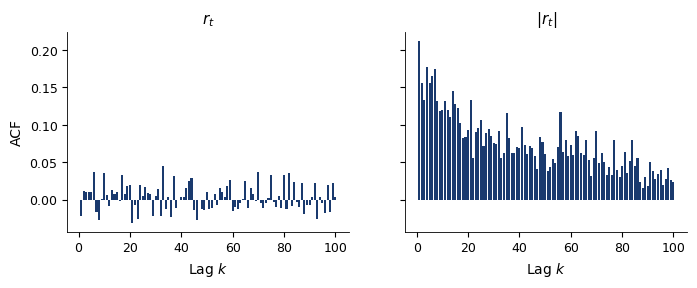

acf1 r = -0.022  acf1 |r| = 0.213
    lb_stat  lb_pvalue
10   20.178      0.028
    lb_stat  lb_pvalue
10  212.745        0.0
ARCH-LM(5) = 114.7


In [ ]:
# Rezolvare
r = rets['btc']
fig, ax = plt.subplots(1, 2, figsize=(8, 2.6), sharey=True)
for axi, s_, t in [(ax[0], r, '$r_t$'), (ax[1], r.abs(), '$|r_t|$')]:
    axi.bar(range(1, 101), acf(s_, nlags=100, fft=True)[1:], color=MainBlue); axi.set_title(t)
    axi.set_xlabel('Lag $k$')
ax[0].set_ylabel('ACF')
plt.show()
print('acf1 r =', round(r.autocorr(1), 3), ' acf1 |r| =', round(r.abs().autocorr(1), 3))
print(acorr_ljungbox(r, lags=[10]).round(3)); print(acorr_ljungbox(r**2, lags=[10]).round(3))
print('ARCH-LM(5) =', round(het_arch(r - r.mean(), nlags=5)[0], 1))

### B4. Ljung–Box robust la heteroscedasticitate [Rezolvat]

- S&P 500, BET-TR, EUR/RON, Bitcoin: $Q(10)$ clasic și $\tilde Q(10) = \sum_k \hat\rho_k^2/\hat\tau_k$ robust, $\hat\tau_k = \sum x_t^2x_{t-k}^2/(\sum x_t^2)^2$ (Lobato, Nankervis și Savin, 2001), și varianta Dalla–Giraitis–Phillips (2022), care păstrează termenii încrucișați semnificativi $E[x_t^2x_{t-j}x_{t-k}]$.
- Interpretare:
  - pentru ce serie rămîne semnificativă autocorelația?
  - ce ipoteze (moment de ordinul patru finit, termeni încrucișați nuli) presupune $\tilde Q$?

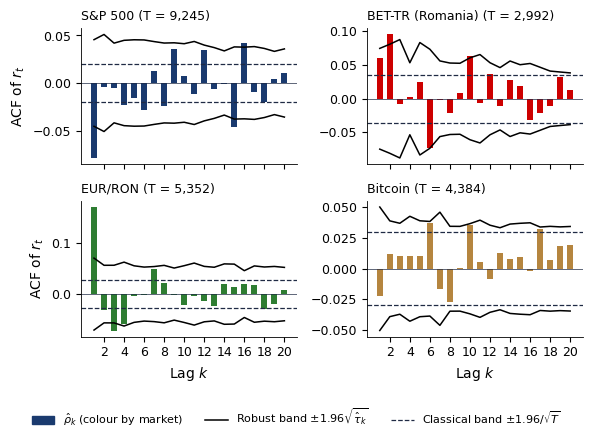

,T,Q10,Q10_p,Qt10,Qt10_p,sig_classic,sig_robust,robust_lags,rho1,Q_DGP,Q_DGP_p,n_cross_terms
asset,,,,,,,,,,,,
S&P 500,9245,91.553,0.000,18.976,0.041,8,3,"[1, 15, 16]",-0.079,18.976,0.041,0
BET-TR (Romania),2992,69.976,0.000,16.923,0.076,5,2,"[2, 10]",0.061,16.923,0.076,0
EUR/RON,5352,221.658,0.000,37.366,0.000,6,2,"[1, 3]",0.170,36.330,0.000,10
Bitcoin,4384,20.178,0.028,11.869,0.294,3,0,[],-0.022,11.869,0.294,0


In [ ]:
# Rezolvare
def dgp_q(r, m=10, lam=2.576):
    """Dalla, Giraitis & Phillips (2022): Q = t' R*^{-1} t, t_k = sum e_t e_{t-k} / sqrt(sum e_t^2 e_{t-k}^2);
    R* keeps only the significant cross terms (|tau_jk| > 2.576). R* = I gives the diagonal Q-tilde."""
    e = (r - r.mean()).values
    P = np.array([np.r_[np.zeros(k), e[k:] * e[:-k]] for k in range(1, m + 1)])
    d = np.sqrt((P ** 2).sum(1))
    t = P.sum(1) / d
    R = (P @ P.T) / np.outer(d, d)
    for j in range(m):
        for k in range(m):
            if j != k:
                pp = P[j] * P[k]
                if abs(pp.sum() / np.sqrt((pp ** 2).sum())) < lam:
                    R[j, k] = 0.0
    q = float(t @ np.linalg.solve(R, t))
    return q, float(stats.chi2.sf(q, m)), int((R != 0).sum() - m)


def robust_lb_table(assets=('sp500', 'bettr', 'eurron', 'btc'), m_q=10, m_band=20):
    rows = []
    for a in assets:
        x = (rets[a] - rets[a].mean()).values
        T, s2 = len(x), np.sum(x ** 2)
        ks = np.arange(1, m_band + 1)
        rho = np.array([np.sum(x[k:] * x[:-k]) / s2 for k in ks])
        tau = np.array([np.sum(x[k:] ** 2 * x[:-k] ** 2) / s2 ** 2 for k in ks])
        q = acorr_ljungbox(rets[a], lags=[m_q], return_df=True)
        qt = float(np.sum(rho[:m_q] ** 2 / tau[:m_q]))
        rows.append({'asset': LABELS[a], 'T': T, 'Q10': float(q['lb_stat'].iloc[0]), 'Q10_p': float(q['lb_pvalue'].iloc[0]),
                     'Qt10': qt, 'Qt10_p': float(stats.chi2.sf(qt, m_q)),
                     'sig_classic': int(np.sum(np.abs(rho) > 1.96 / np.sqrt(T))),
                     'sig_robust': int(np.sum(np.abs(rho) > 1.96 * np.sqrt(tau))),
                     'robust_lags': [int(k) for k in ks[np.abs(rho) > 1.96 * np.sqrt(tau)]], 'rho1': rho[0],
                     **dict(zip(['Q_DGP', 'Q_DGP_p', 'n_cross_terms'], dgp_q(rets[a], m_q)))})
    return pd.DataFrame(rows).set_index('asset')


def fig_robust_acf(assets=('sp500', 'bettr', 'eurron', 'btc'), m=20):
    """ACF of r_t (lags 1..m) with the classical i.i.d. band and the heteroskedasticity-robust band, 2 x 2 grid."""
    fig, axes = plt.subplots(2, 2, figsize=(6.0, 4.0), sharex=True)
    for ax, a in zip(axes.ravel(), assets):
        x = (rets[a] - rets[a].mean()).values
        T, s2 = len(x), np.sum(x ** 2)
        ks = np.arange(1, m + 1)
        rho = np.array([np.sum(x[k:] * x[:-k]) / s2 for k in ks])
        tau = np.array([np.sum(x[k:] ** 2 * x[:-k] ** 2) / s2 ** 2 for k in ks])
        ax.bar(ks, rho, color=COLORS[a], width=0.6, label='$\\hat\\rho_k$')
        ax.plot(ks, 1.96 * np.sqrt(tau), color='black', lw=1.1, label='Robust band $\\pm1.96\\sqrt{\\hat\\tau_k}$')
        ax.plot(ks, -1.96 * np.sqrt(tau), color='black', lw=1.1)
        ax.axhline(1.96 / np.sqrt(T), color=Navy, ls='--', lw=0.9, label='Classical band $\\pm1.96/\\sqrt{T}$')
        ax.axhline(-1.96 / np.sqrt(T), color=Navy, ls='--', lw=0.9)
        ax.axhline(0, color=Navy, lw=0.5)
        ax.set_xticks(ks[1::2])
        ax.set_title(f'{LABELS[a]} (T = {T:,})', fontsize=9, loc='left')
    for ax in axes[1]:
        ax.set_xlabel('Lag $k$')
    for ax in axes[:, 0]:
        ax.set_ylabel('ACF of $r_t$')
    h = [plt.Rectangle((0, 0), 1, 1, color=MainBlue), plt.Line2D([], [], color='black', lw=1.1),
         plt.Line2D([], [], color=Navy, ls='--', lw=0.9)]
    l = ['$\\hat\\rho_k$ (colour by market)', 'Robust band $\\pm1.96\\sqrt{\\hat\\tau_k}$', 'Classical band $\\pm1.96/\\sqrt{T}$']
    plt.tight_layout()
    fig.legend(h, l, loc='upper center', bbox_to_anchor=(0.5, 0.0), ncol=3, frameon=False)
    save_fig('ch1_sem_robust_acf')


fig_robust_acf()
robust_lb_table().round(3)

### B5. Gaussianitate prin agregare (Bitcoin), cu erori standard aproximative [Propus]

SE: Standard Error --- eroare standard.

- **Model**: [B1](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-B1) și [B3](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-B3) \[Rezolvat\]; secțiunea [B5](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-B5) din notebook

- **Întrebare**: se apropie randamentele Bitcoin pe $h$ zile de distribuția Normală cînd $h$ crește?

- **Date**: `r_btc`, $T = 4\,384$, în blocuri care nu se suprapun, începînd cu prima zi

  - primul bloc de 5 zile este 18--22 sept. 2014, al doilea 23--27 sept. 2014

  - ultimul bloc incomplet (4 zile pentru $h = 5$ și $h = 20$) se elimină

- **Cerințe**

  1.  Construiți randamentele logaritmice pe $h$ zile (sume de $h$ randamente zilnice consecutive) pentru $h = 1, 5, 20$.

  2.  Reprezentați un QQ plot al fiecărei serii standardizate față de distribuția Normală, cu $N$, numărul de blocuri, în titlu.

  3.  Calculați excesul de kurtosis și SE de referință pentru date i.i.d. cu distribuția Normală, $\sqrt{24/N}$.

      - $\sqrt{24/N}$: eroarea standard a excesului de kurtosis estimat din $N$ observații i.i.d. Normale (24, ca în JB)

- **De raportat**: cele trei QQ plot-uri și un tabel $h$, $N$, exces de kurtosis, $\sqrt{24/N}$

- **Interpretare**

  - de ce subestimează $\sqrt{24/N}$ incertitudinea în acest caz?

  - de ce blocurile disjuncte, deși nu au zile comune, nu elimină dependența volatilității?

[Exercițiul B5 în seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-B5)

In [ ]:
# Codul vostru aici


### B7. Kurtosisul care nu converge [Propus]

- **Model**: [B1](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-B1) \[Rezolvat\]; secțiunea [B7](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-B7) din notebook

- **Date**: `r_sp`; fereastra $n$ cuprinde randamentele anterioare datei de 3 ianuarie a anului $1990 + n$, $n = 1, \dots, 36$

  - 253 de randamente pentru $n = 1$, 2 527 pentru $n = 10$, 9 067 pentru $n = 36$

- **Simulare**: 500 de traiectorii Student-$t$ de lungime 9 245 pentru $\nu = 3$ și pentru $\nu = 6$ (`default_rng(42)`)

  - trunchiate la aceleași lungimi ale ferestrelor

- **Cerințe**

  1.  Calculați excesul de kurtosis al S&P 500 pe fiecare fereastră.

  2.  Identificați cele mai mari trei salturi și zilele care le generează.

  3.  Pentru fiecare $\nu$ calculați cuantilele de 5%, 50% și 95% ale kurtosisului simulat pentru fiecare $n$.

  4.  Reprezentați curba empirică suprapusă peste ambele benzi, pe o scală logaritmică simetrică.

- **Interpretare**

  - de ce se stabilizează lent banda pentru $\nu = 6$, deși kurtosisul lui $t_6$ este finit?

  - ce informație transmite, în acest caz, valoarea "exces de kurtosis $= 10{,}9$"?

- **De raportat**: kurtosis pe ferestre cumulative, benzi de cuantile simulate și cele mai mari trei salturi.

[Exercițiul B7 în seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-B7)

In [ ]:
# Codul vostru aici


### B8. Faptele stilizate reproduse de un GARCH(1,1)-t [Propus]

- **Model**: [B3](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-B3) și [B6](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-B6) \[Rezolvat\], [A10](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-A10); secțiunea [B8](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-B8) din notebook

- **Date**: `r_sp` exprimat în % ($T = 9\,245$)

  - medie constantă

  - $\omega$ în %$^2$ pe zi

``` {.python language="Python"}
from arch import arch_model
from arch.univariate import StudentsT
am  = arch_model(100 * r_sp, mean='Constant', vol='GARCH', p=1, q=1, dist='t')
res = am.fit(disp='off')
am.distribution = StudentsT(seed=np.random.default_rng(42))  # reproducible paths
sim = am.simulate(res.params, nobs=len(r_sp), burn=1000)['data']
```

- **Cerințe**

  1.  Estimați modelul și raportați toți cei cinci parametri, cu unitățile lor.

  2.  Verificare: simulați o traiectorie și calculați-i excesul de kurtosis.

  3.  Apoi simulați 200 de traiectorii.

  4.  Pentru fiecare traiectorie, calculați următoarele statistici.

      - excesul de kurtosis

      - ACF a lui $|r_t|$ la lagurile 1, 20, 100, 250

      - $\hat\alpha$ Hill pentru $|r_t|$ la $k = 2\%$ din $T$

      - $L(1) = \text{corr}(r_t, |r_{t+1}|)$: corelația dintre randamentul de azi și mărimea celui de mîine (leverage effect, [B9](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-B9))

  5.  Construiți intervalele 5--95%, separat pentru fiecare statistică.

  6.  Precizați, pentru fiecare valoare observată, dacă se află în interiorul intervalului.

- **Interpretare**

  - ce fapte stilizate nu sînt reproduse?

  - ce componentă a modelului ar trebui modificată pentru fiecare dintre ele?

- **De raportat**: statistici observate lîngă intervalele simulate și modificări propuse modelului.

[Exercițiul B8 în seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-B8)

In [ ]:
# Codul vostru aici


### B9. Leverage effect: România (BET-TR) față de cripto (Bitcoin) [Propus]

- **Model**: [B3](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-B3) \[Rezolvat\]; secțiunea [B9](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-B9) din notebook

- **Convenția lagului**: $L(k) = \text{corr}(r_t, |r_{t+k}|)$ [Christie (1982)](https://doi.org/10.1016/0304-405X(82)90018-6)

  - $L(k) < 0$: după scăderi, randamentele ulterioare sînt mai mari în valoare absolută (leverage effect)

  - $k$ este exprimat în zile de observație ale fiecărei serii

  - pentru $k > 0$, randamentul curent este asociat cu o valoare absolută ulterioară

  - exemplu, $k = 1$: randamentul BET-TR de luni, 16 mar. 2020, este asociat cu $|r|$ de marți, 17 mar. 2020

- **Date**: `r_bet` și `r_btc`, fiecare pe propriul calendar

- **Cerințe**

  1.  Calculați $L(k)$ pentru $k = -20, \dots, 20$.

  2.  Reprezentați ambele serii cu benzile de referință i.i.d. $\pm 1{,}96/\sqrt{T}$ (0,036 și 0,030).

<!-- -->

- **Cerințe** (continuare)

  3.  Raportați $L(1)$ și $L(5)$ pentru ambele piețe.

  4.  Precizați dacă se află în afara benzilor de referință.

  5.  Propuneți două explicații alternative pentru un efect mai slab la Bitcoin.

- **Interpretare**

  - de ce o bandă de referință nu este un interval de încredere în prezența volatility clustering?

  - ce informație suplimentară oferă [B10](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-B10)?

[Exercițiul B9 în seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-B9)

In [ ]:
# Codul vostru aici


### B10. Leverage effect ca regresie (erori standard Newey–West, variabile de control |r|) [Propus]

- **Model**: [B4](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-B4) \[Rezolvat\], [B9](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-B9); secțiunea [B10](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-B10) din notebook

- **Regresia**: $|r_{t+1}| = c + \beta^+ r_t^+ + \beta^- r_t^- + \sum_{j=1}^{5}\delta_j|r_{t-j}| + u_{t+1}$

  - $r_t^+ = \max(r_t, 0) \geq 0$, $r_t^- = \min(r_t, 0) \leq 0$: partea pozitivă și partea negativă a randamentului

  - $c$: constanta; $\delta_j$: efectul lui $|r_{t-j}|$, variabile de control pentru volatility clustering; $u_{t+1}$: eroarea

  - un cîștig $+a$ contribuie cu $\beta^+ a$, o pierdere $-a$ contribuie cu $-\beta^- a$

  - un răspuns simetric înseamnă $\beta^+ = -\beta^-$

  - rîndul din matricea de regresori pentru ziua $t$: $(1,\ r_t^+,\ r_t^-,\ |r_{t-1}|, \dots, |r_{t-5}|)$

  - variabila dependentă: $|r_{t+1}|$

- **Date**: `r_sp`, `r_bet`, `r_btc`, `r_eur`

- **Cerințe**

  1.  Estimați prin Ordinary Least Squares (OLS) cu erori standard Newey--West [Newey & West (1987)](https://doi.org/10.2307/1913610), robuste la heteroscedasticitate și autocorelație, cu lungimea de trunchiere $\lfloor 4(T/100)^{2/9}\rfloor$ (numărul de laguri ale erorilor luate în calcul).

  2.  Testați $H_0\!: \beta^+ + \beta^- = 0$ (răspuns simetric) la 5%, față de $\chi^2_1$, cu statistica Wald

      - $W = (\hat\beta^+ + \hat\beta^-)^2/[\text{Var}(\hat\beta^+) + \text{Var}(\hat\beta^-) + 2\,\text{Cov}(\hat\beta^+, \hat\beta^-)]$

      - numitorul: varianța lui $\hat\beta^+ + \hat\beta^-$, din matricea de covarianță Newey--West; $W$ este pătratul unei statistici $t$

  3.  Reprezentați valoarea estimată a lui $|r_{t+1}|$ după un cîștig $+a$ și după o pierdere $-a$, cu variabilele de control fixate la mediile lor.

  4.  Arătați de ce $|r_t|$ nu poate fi adăugat printre variabilele de control.

- **De raportat**: tabelul coeficienților, test Wald, graficul răspunsului și explicația coliniarității.

[Exercițiul B10 în seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-B10)

In [ ]:
# Codul vostru aici


### B11. EUR/RON pe regimuri [Propus]

HAC: Heteroskedasticity and Autocorrelation Consistent --- erori standard care permit dispersie variabilă și autocorelație.

- **Model**: [B1](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-B1), [B4](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-B4) \[Rezolvat\]; secțiunea [B11](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-B11) din notebook

- **Date**: `r_eur` (cursul de referință Banca Națională a României (BNR)), seria împărțită în trei perioade

  - iul. 2005 -- 2011, 2012--2019, 2020--2026: 1 656, 2 013, 1 683 de randamente

  - lagurile se construiesc în interiorul fiecărei perioade

- **Cerințe**

  1.  Pentru fiecare perioadă, estimați prin OLS regresia $r_t = a + \rho\,r_{t-1} + e_t$, cu SE HAC (lungimea de trunchiere $\lfloor 4(T/100)^{2/9}\rfloor$).

      - $a$: constanta; $\rho$: autocorelația de lag 1; $e_t$: eroarea

      - SE HAC: eroare standard robustă la heteroscedasticitate și autocorelație (ca la [B10](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-B10))

  2.  Raportați $\hat\rho$, SE, volatilitatea și excesul de kurtosis pentru fiecare perioadă.

- **Cerințe** (continuare)

  3.  Testați egalitatea lui $\rho$ între perioade cu statistica de mai jos. \[ W = \sum_j w_j(\hat\rho_j - \bar\rho)^2 \sim \chi^2_2 \] Reperul presupune estimări asimptotic independente între cele trei perioade.

      - $j = 1, 2, 3$: perioada; ponderi $w_j = 1/\text{SE}_j^2$, deci estimările precise contează mai mult

      - $\bar\rho = \sum_j w_j\hat\rho_j/\sum_j w_j$: media ponderată a celor trei estimări

      - $W$ măsoară dispersia estimărilor în jurul lui $\bar\rho$; 2 grade de libertate = 3 perioade $-$ 1

CUSUM: CUmulative SUM (of squares) --- suma cumulată (a pătratelor).

- **Cerințe** (continuare)

  4.  Separat, identificați o ruptură în varianță cu suma cumulată a pătratelor (CUSUM) [Inclán & Tiao (1994)](https://doi.org/10.1080/01621459.1994.10476824).

      - $C_k = \sum_{t \leq k} x_t^2$: suma pătratelor pînă în ziua $k$; $x_t$ este randamentul minus media întregii serii

      - $D_k = C_k/C_T - k/T$: fracțiunea din varianța totală acumulată pînă în ziua $k$, minus fracțiunea de timp scursă

      - $D_k \approx 0$ pentru orice $k$ dacă varianța este constantă

      - ruptura este estimată la $\arg\max_k |D_k|$, ziua $k$ în care $|D_k|$ este maxim

- **Interpretare**

  - de ce este atît de mare SE pentru 2020--2026?

  - de ce data rupturii identificată prin CUSUM are caracter descriptiv și nu constituie un test?

[Exercițiul B11 în seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-B11)

In [ ]:
# Codul vostru aici


### B12. Memorie lungă sau rupturi structurale: estimatorul Whittle local al lui d pentru |r_t| [Propus]

- **Model**: [B4](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-B4), [B6](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-B6) \[Rezolvat\]; secțiunea [B12](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-B12) din notebook (funcția `local_whittle(x, m)`)

- **Parametrul de memorie** $d$: viteza cu care descrește ACF a lui $x_t = |r_t|$

  - $d = 0$: memorie scurtă, ACF descrește geometric

  - $0 < d < 0{,}5$: memorie lungă staționară, ACF descrește lent, ca $k^{2d-1}$

  - $d \geq 0{,}5$: seria nu mai este staționară

- **Date**: $|r_t|$ pentru S&P 500, BET-TR și Bitcoin

- **Metoda local Whittle** [Robinson (1995)](https://doi.org/10.1214/aos/1176324317): centrați $x_t = |r_t|$

  - frecvențele Fourier $\lambda_j = 2\pi j/T$, $j = 1, \dots, m$; frecvențele mici corespund ciclurilor lungi

  - periodograma $I(\lambda) = \frac{1}{2\pi T}\big|\sum_t x_t e^{-\mathrm{i}\lambda t}\big|^2$: intensitatea ciclurilor de frecvență $\lambda$ din serie

  - memoria lungă face ca $I(\lambda_j)$ să crească proporțional cu $\lambda_j^{-2d}$ la frecvențe mici

- $\hat d$ minimizează pe $d \in [-0{,}49;\ 0{,}99]$ \[ \ln\Big(\frac1m\sum_{j=1}^m \lambda_j^{2d}I(\lambda_j)\Big) - \frac{2d}{m}\sum_{j=1}^m \ln\lambda_j \]

  - $m = \lfloor T^{p}\rfloor$: numărul de frecvențe mici folosite; $p \in (0, 1)$ stabilește lățimea de bandă

  - $\text{SE} = 1/(2\sqrt m)$

- **Cerințe**

  1.  Estimați $d$ cu $p = 0{,}65$ și raportați intervalul de încredere de 95%.

  2.  Reprezentați $\hat d$ în funcție de $p$ de la 0,45 la 0,80, cu dreptele $d = 0$ și $d = 0{,}5$.

  3.  Identificați o ruptură în varianța lui $r_t$ ([B11](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-B11)).

  4.  Reestimați $\hat d$ de fiecare parte a rupturii.

  5.  Reprezentați ACF a lui $|r_t|$ înainte și după ruptură.

- **Interpretare**

  - este $\hat d > 0$ robust la $p$ și la ruptură?

  - este rezultatul compatibil și cu un model cu regimuri [Diebold & Inoue (2001)](https://doi.org/10.1016/S0304-4076(01)00073-2)?

  - ce implică $\hat d \geq 0{,}5$?

- **De raportat**: estimări ale parametrului de memorie și intervale, grafic pe bandwidth, data rupturii și ACF înainte/după.

[Exercițiul B12 în seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-B12)

In [ ]:
# Codul vostru aici


### B13. BET-TR față de S&P 500 pe aceeași perioadă [Propus]

- **Model**: [A1](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-A1), [B1](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-B1) \[Rezolvat\]; secțiunea [B13](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-B13) din notebook

- **Date**: BET-TR (randament total, lei) și S&P 500 (indice de preț, United States dollar (USD))

  - aliniați *prețurile* pe zilele comune (23 sept. 2014 -- 18 sept. 2026)

  - apoi calculați cele 2 903 randamente

  - lungimea intervalelor: 2 231 de o zi, 538 de două sau trei zile, 134 mai lungi (cel mult 6 zile)

- **Cerințe**

  1.  Reprezentați valoarea investiției, rebazată (scală logaritmică), și cele două curbe de drawdown (underwater), $DD_t$ din [A2(a)](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-A2a).

  2.  Calculați următoarele măsuri pentru ambii indici.

      - CAGR $= (P_{\text{final}}/P_{\text{inițial}})^{1/Y} - 1$, cu $Y$ numărul de ani calendaristici; volatilitatea randamentelor simple ($A = 252$, prin convenție; pe zilele comune sînt circa 242 de randamente pe an)

      - raportul Sharpe $252\bar R/(\sqrt{252}\,\hat\sigma_R)$ cu $r_f = 0$: randamentul anual pe unitatea de volatilitate

      - $\bar R$, $\hat\sigma_R$: media și abaterea standard a randamentelor simple zilnice; $r_f$: rata dobînzii fără risc

      - raportul Sortino [Sortino & van der Meer (1991)](https://doi.org/10.3905/jpm.1991.409343) $252\bar R/(\sqrt{252}\,\hat\sigma_D)$, cu semiabaterea inferioară $\hat\sigma_D = \sqrt{\frac1T\sum_t \min(R_t, 0)^2}$, calculată pe toate zilele

      - Sortino penalizează doar zilele cu pierderi

      - maximum drawdown (MDD) și raportul Calmar ([A2(a)](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-A2a))

- **De raportat**: graficul și un tabel cu două coloane

- **Interpretare**: indicați trei motive pentru care comparația este doar descriptivă

[Exercițiul B13 în seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-B13)

In [ ]:
# Codul vostru aici


### B14. Semnificația diferenței dintre rapoartele Sharpe (Jobson–Korkie cu corecția Memmel, bootstrap pe blocuri) [Propus]

- **Model**: [B1(d)](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-B1d), [B13](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-B13); secțiunea [B14](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-B14) din notebook

- **Referință**: eroarea standard a raportului Sharpe, [Lo (2002)](https://doi.org/10.2469/faj.v58.n4.2453)

- **Date**: cele 2 903 perechi de randamente din [B13](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-B13)

  - randamente simple pentru rapoartele Sharpe (calculate în [B13](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-B13)) și corelația din test

  - randamente logaritmice pentru comparațiile de calendar de la cerința 5

- **Cerințe**

  1.  Convertiți rapoartele Sharpe în valori zilnice ($\widehat{SR}/\sqrt{252}$).

  2.  Calculați testul Jobson--Korkie [Jobson & Korkie (1981)](https://doi.org/10.1111/j.1540-6261.1981.tb04891.x) cu corecția lui [Memmel (2003)](https://scholar.google.com/scholar?q=%22Performance+hypothesis+testing+with+the+Sharpe+ratio%22+Memmel+2003).

      - $z = (\widehat{SR}_1 - \widehat{SR}_2)/\sqrt{\hat V}$

      - $\hat V = \frac1T\big[2(1-\hat\rho) + \tfrac12(\widehat{SR}_1^2 + \widehat{SR}_2^2 - 2\widehat{SR}_1\widehat{SR}_2\hat\rho^2)\big]$

      - $\widehat{SR}_1, \widehat{SR}_2$: rapoartele Sharpe zilnice ale BET-TR și S&P 500; $\hat\rho$: corelația randamentelor lor

      - $\hat V$: varianța estimată a diferenței; sub $H_0$ (rapoarte Sharpe egale) $z \approx N(0,1)$

- **Cerințe** (continuare)

  3.  Aplicați un bootstrap circular pe blocuri, pe perechi de randamente, cu 2 000 de reeșantionări (`default_rng(42)`).

      - extrageți $\lceil T/21\rceil$ zile de început, preluați cîte 21 de zile consecutive (circular, reluînd seria de la început), trunchiați la $T$

      - aplicați **aceiași** indici ambelor serii

  4.  Raportați intervalul percentil de 95% pentru diferența anualizată.

  5.  Calculați patru corelații.

      - în aceeași zi

      - BET-TR cu S&P 500 din ziua precedentă și din ziua următoare

      - pe randamente săptămînale (vineri)

- **Interpretare**

  - este diferența semnificativă?

  - ce presupun cele două metode?

  - ce corelație trebuie folosită la construcția unui portofoliu?

[Exercițiul B14 în seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-B14)

In [ ]:
# Codul vostru aici


### B15. Estimatori de range volatility pe S&P 500 (2008–2026) [Propus]

- **Model**: [A8](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-A8) \[Rezolvat\]; secțiunea [B15](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-B15) din notebook

  - notebook-ul conține funcțiile pentru toți cei cinci estimatori

  - formulele se găsesc în [Capitolul 1](https://danpele.github.io/MFM/RO/Cursuri/capitol1_fapte_stilizate.pdf)

- **Date**: Open, High, Low, Close (OHLC) pentru indicele S&P 500, 2 ian. 2008 -- 18 sept. 2026

- ETF-ul SPY, cu toate prețurile ajustate pe aceeași bază

  - $C^*$ = închiderea ajustată (pentru dividende și splituri)

  - $O^*, H^*, L^* = (C^*/C) \times O, H, L$, cu $C$ închiderea neajustată și $C^*/C$ factorul de ajustare al zilei

  - exemplu, 16 mar. 2020: factorul $218{,}08/239{,}85 = 0{,}9092$; $O^* = 241{,}18 \times 0{,}9092 = 219{,}29$, $H^* = 233{,}58$, $L^* = 215{,}82$

- **Cerințe**

  1.  Calculați volatilitățile rolling pe 21 de zile close-to-close, Parkinson, Garman--Klass [Garman & Klass (1980)](https://doi.org/10.1086/296072), Rogers--Satchell [Rogers & Satchell (1991)](https://doi.org/10.1214/aoap/1177005835) și Yang--Zhang [Yang & Zhang (2000)](https://doi.org/10.1086/209650) ($A = 252$).

  2.  Calculați mediile lor în timp.

  3.  Pentru indice și pentru SPY, comparați mediile estimatorilor close-to-close și Yang--Zhang pe 21 de zile cu două volatilități calculate pe întregul eșantion.

      - volatilitatea de peste noapte: $\text{sd}(o_t - c_{t-1})\sqrt{252}$, cu $o_t - c_{t-1}$ randamentul logaritmic de peste noapte (notațiile din [A8](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-A8))

      - volatilitatea de la deschidere la închidere: $\text{sd}(c_t - o_t)\sqrt{252}$

      - $\text{sd}$: abaterea standard de selecție

- **Interpretare**: de ce rămîne Yang--Zhang sub close-to-close pe indice, dar nu și pe SPY?

- **De raportat**: tabel cu volatilitățile medii și explicația contribuției de peste noapte.

[Exercițiul B15 în seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-B15)

In [ ]:
# Codul vostru aici


## După curs — A5, B6, A6

- Seminarul 1 are loc înaintea Cursului 1: aceste cerințe folosesc instrumente introduse la curs (tail index-ul Hill și varianța autocorelației); rezolvați-le după curs, înaintea seminarului următor.

### A5. Estimatorul Hill, pas cu pas (eșantion ipotetic) [Rezolvat]

- Cele mai mari 11 randamente absolute (%) 12,0, 9,5, 8,2, 7,4, 6,9, 6,1, 5,8, 5,5, 5,2, 5,0, 4,8: calculați estimarea Hill pentru $k = 10$, SE și intervalul de 95%; repetați pe BET-TR.
- Interpretare: se poate stabili dacă momentul de ordinul patru există?

In [ ]:
# A5 Estimatorul Hill, pas cu pas (eșantion ipotetic)
X = np.array([12.0, 9.5, 8.2, 7.4, 6.9, 6.1, 5.8, 5.5, 5.2, 5.0, 4.8])
k = 10
logs = np.log(X[:k] / X[k]); alpha = 1 / logs.mean(); se = alpha / np.sqrt(k)
print('logs =', logs.round(3), ' sum =', round(logs.sum(), 3))
print(f'alpha = {alpha:.2f}  SE = {se:.2f}  95% = [{alpha - 1.96 * se:.2f}, {alpha + 1.96 * se:.2f}]')
# același calcul pe cele mai mari 11 zile BET-TR
x = np.sort(rets['bettr'].abs().values)[::-1][:11] * 100
print('BET-TR:', x.round(3), ' alpha_10 =', round(1 / np.mean(np.log(x[:10] / x[10])), 2))

logs = [0.916 0.683 0.536 0.433 0.363 0.24  0.189 0.136 0.08  0.041]  sum = 3.616
alpha = 2.77  SE = 0.87  95% = [1.05, 4.48]
BET-TR: [11.857 10.075  7.827  6.707  6.662  6.512  5.972  5.928  5.49   5.285
  5.202]  alpha_10 = 3.38


### B6. Estimatorul Hill pe ambele cozi, BET-TR și Bitcoin [Rezolvat]

- BET-TR și Bitcoin: grafice Hill pentru pierderi și cîștiguri, estimări la $k = 2\%$ din $n$ cu intervale de 95% $\hat\alpha(1 \pm 1,96/\sqrt{k})$ și un test $z$ al egalității cozilor; intervalele și testul presupun observații independente în coadă (reper i.i.d.).
- Interpretare:
  - dacă valorile extreme sînt grupate în timp, SE adevărată este mai mare sau mai mică?
  - care dintre $\hat\alpha$ și $\hat\nu$ Student-t descrie coada?

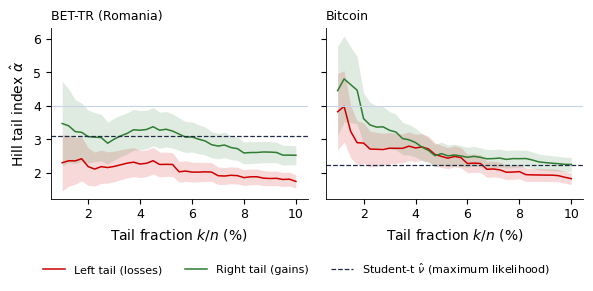

asset,BET-TR (Romania),Bitcoin
n,2992,4384
k,59,87
alpha_left,2.189264,2.890881
ci_left,"(1.6306288103270705, 2.7478988849206885)","(2.283408794914191, 3.498354084353436)"
alpha_right,3.084439,3.620397
ci_right,"(2.2973816746320073, 3.871495770206749)","(2.8596285657231864, 4.381166129741307)"
z_diff,-1.817879,-1.468704
p_diff,0.069083,0.141913
nu_mle,3.097034,2.229264


In [ ]:
# Rezolvare
def hill_tails(assets=('bettr', 'btc'), frac=0.02):
    rows = []
    for a in assets:
        r = rets[a]
        k = int(frac * len(r))
        aL, aR = hill_estimator(-r.values, k), hill_estimator(r.values, k)
        z = (r - r.mean()) / r.std()
        nu = stats.t.fit(z)[0]
        zdiff = (aL - aR) / np.sqrt(aL ** 2 / k + aR ** 2 / k)
        rows.append({'asset': LABELS[a], 'n': len(r), 'k': k, 'alpha_left': aL,
                     'ci_left': (aL * (1 - 1.96 / np.sqrt(k)), aL * (1 + 1.96 / np.sqrt(k))),
                     'alpha_right': aR,
                     'ci_right': (aR * (1 - 1.96 / np.sqrt(k)), aR * (1 + 1.96 / np.sqrt(k))),
                     'z_diff': zdiff, 'p_diff': 2 * stats.norm.sf(abs(zdiff)), 'nu_mle': nu})
    return pd.DataFrame(rows).set_index('asset')


def fig_hill_tails(assets=('bettr', 'btc')):
    fig, axes = plt.subplots(1, len(assets), figsize=(6.0, 2.6), sharey=True)
    for ax, a in zip(axes, assets):
        r = rets[a].values
        for side, x, c, lab in [('left', -r, IDAred, 'Left tail (losses)'), ('right', r, Forest, 'Right tail (gains)')]:
            ks = np.array([max(int(f * len(r)), 5) for f in HILL_FRACS_TAILS])
            al = np.array([hill_estimator(x, k) for k in ks])
            ax.plot(100 * HILL_FRACS_TAILS, al, color=c, lw=1.1, label=lab)
            ax.fill_between(100 * HILL_FRACS_TAILS, al * (1 - 1.96 / np.sqrt(ks)), al * (1 + 1.96 / np.sqrt(ks)),
                            color=c, alpha=0.15, lw=0)
        z = (rets[a] - rets[a].mean()) / rets[a].std()
        ax.axhline(stats.t.fit(z)[0], color=Navy, ls='--', lw=0.9, label='Student-t $\\hat\\nu$ (maximum likelihood)')
        ax.axhline(4, color=BandBlue, lw=0.8)
        ax.set_title(LABELS[a], fontsize=9, loc='left')
        ax.set_xlabel('Tail fraction $k/n$ (%)')
    axes[0].set_ylabel('Hill tail index $\\hat\\alpha$')
    h, l = axes[0].get_legend_handles_labels()
    fig.legend(h, l, loc='upper center', bbox_to_anchor=(0.5, 0.02), ncol=3, frameon=False)
    plt.tight_layout()
    save_fig('ch1_sem_hill_tails')


fig_hill_tails()
hill_tails().T

### A6. Lărgirea benzii autocorelației în prezența volatility clustering [Propus]

- **Model**: [A4](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-A4) \[Rezolvat\]; secțiunea [A6](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-A6) din notebook

- **Cadru**: $x_t = \sigma_t\varepsilon_t$, cu $\varepsilon_t$ i.i.d. $N(0,1)$, independent de procesul staționar al volatilității

  - în acest caz, $x_t$ este necorelat serial

  - $\text{Var}(\hat\rho_1) \approx v_1/T$, cu $v_1 = \mathbb{E}[x_t^2x_{t-1}^2]/(\mathbb{E} x_t^2)^2$ [Lobato, Nankervis & Savin (2001)](https://doi.org/10.1111/1468-2354.00106)

  - $v_1$: factorul cu care volatility clustering crește varianța lui $\hat\rho_1$ față de valoarea i.i.d. $1/T$

- **Date de intrare**

  - [A4](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-A4): $\mathbb{E}\sigma^2 = 1{,}6$, $\text{Var}(\sigma^2) = 4{,}0 - 1{,}6^2 = 1{,}44$ (în %$^4$)

  - regimuri persistente ([A9](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-A9)): $\text{Cov}(\sigma_t^2, \sigma_{t-1}^2) = \lambda\,\text{Var}(\sigma^2)$ cu $\lambda = 0{,}875$

  - $\lambda \in [0, 1)$: persistența regimurilor; $\lambda = 0$: stări independente de la o zi la alta

  - S&P 500: $T = 9\,245$, $\hat\rho_1 = -0{,}079$, $T\hat\tau_1 = 5{,}00$

- **Cerințe**

  1.  Arătați că $v_1 = 1$ pentru mixtura din [A4](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-A4), ale cărei stări sînt independente de la o zi la alta.

  2.  Arătați că $v_1 = 1 + \lambda\,\text{Var}(\sigma^2)/(\mathbb{E}\sigma^2)^2$ pentru regimuri persistente.

  3.  Calculați $v_1$ și factorul de lărgire a benzii $\sqrt{v_1}$.

  4.  Comparați cu [B4](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-B4): calculați statistica $t = \hat\rho_1/\text{SE}$ pentru autocorelația de lag 1 a S&P 500 cu SE i.i.d. $1/\sqrt{T}$ și cu SE robustă $\sqrt{\hat\tau_1}$ ($|t| > 1{,}96$: semnificativă la 5%).

  5.  Calculați cele două semilățimi ale benzii de 95%.

- **Interpretare**: ce factor lărgește banda: cozile groase sau volatilitatea persistentă?

- **De raportat**: v1 și rădăcina sa; tabel i.i.d./robust cu statisticile și lățimile benzilor.

[Exercițiul A6 în seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-A6)

In [ ]:
# Codul vostru aici


## Partea C — întrebări deschise și critica unui răspuns AI

### C1. Critica unui răspuns AI [Propus]

- **Model**: [A3](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-A3), [B3](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-B3) și [B4](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-B4) \[Rezolvat\]; secțiunea [C1](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-C1) din notebook

- **Date**: `r_bet`, cele 2 992 de randamente din pregătire

- **Cerințe**

  1.  Identificați toate erorile de fond din cod și din cele trei concluzii.

  2.  Pentru fiecare eroare, precizați cum poate fi detectată.

      - un test pe date simulate sau o valoare din slide-urile introductive

      - un exercițiu rezolvat sau documentația bibliotecii

  3.  Scrieți codul corectat, în formă executabilă.

- **Cerințe** (continuare)

  4.  Raportați excesul de kurtosis, JB cu p-value-ul său, $Q(10)$ pe $r_t$ și pe $r_t^2$ și $\tilde Q(10)$ robust din [B4](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-B4).

  5.  Formulați ipotezele din spatele p-value-ului robust.

  6.  Scrieți concluzia corectată în trei fraze.

- **De raportat**

  - codul corectat

  - un tabel valoare AI / valoare corectă

  - un grafic al ACF pentru $r_t$ și $r_t^2$

- Codul generat de AI se execută de obicei fără mesaje de eroare

  - erorile sînt de natură statistică, nu sintactică

  - consemnați erorile identificate în `AI_ERRORS.md`

[Exercițiul C1 în seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-C1)

In [ ]:
# Codul asistentului, neschimbat (rulează fără mesaj de eroare)
bet = pd.DataFrame({'close': closes['bettr']})
from scipy import stats
from statsmodels.stats.diagnostic import acorr_ljungbox
r = np.log(bet["close"]).diff().dropna()     # daily log returns
k = stats.kurtosis(r)                         # sample kurtosis
print("excess kurtosis:", k - 3)              # the Normal has kurtosis 3
jb, p = stats.jarque_bera(r)
lb = acorr_ljungbox(r**2, lags=[10])          # Ljung-Box, 10 lags
print('JB p-value:', p)
lb

excess kurtosis: 14.79005244943534
JB p-value: 0.0


,lb_stat,lb_pvalue
10,713.54761,7.750836e-147


In [ ]:
# Codul vostru aici


### C2. Autocorelația BET-TR după reclasificarea FTSE din 2020 [Propus]

FTSE: Financial Times Stock Exchange (FTSE Russell, index provider) --- furnizorul de indici FTSE Russell.

- **Model**: [B4](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-B4) \[Rezolvat\], [B11](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-B11); o propunere de proiect

- **Context**: pe piețele mai puțin lichide, randamentele indicilor au adesea o autocorelație pozitivă la lagul 1, din cauza prețurilor neactualizate ale componentelor (stale prices)

- **Ipoteza de testat**: după reclasificare, lichiditatea a crescut, iar autocorelația de lag 1 a BET-TR a scăzut

  - FTSE Russell a reclasificat România ca piață emergentă secundară, începînd cu 21 sept. 2020

- **Date**: `r_bet` și o măsură a lichidității

  - lichiditatea: valoarea zilnică tranzacționată (volum $\times$ preț de închidere brut, în lei) a 11 blue chips de la Bursa de Valori București (BVB)

  - acțiunile: Banca Transilvania (TLV), OMV Petrom (SNP), BRD Groupe Société Générale (BRD), Transgaz (TGN), Fondul Proprietatea (FP), Romgaz (SNG), Hidroelectrica (H2O), Nuclearelectrica (SNN), Electrica (EL), Digi Communications (DIGI), Transelectrica (TEL); fișiere ticker.RO.csv, cîmpuri volume și close

  - însumată pe acțiunile listate în ziua respectivă

  - raportați numărul de acțiuni listate în fiecare an

- **Cerințe**

  1.  Calculați $\hat\rho_1$ pe ferestre rolling de 250 de zile (pas de 5 zile).

  2.  Adăugați în jurul fiecărei estimări rolling intervalul $\hat\rho_1 \pm 1{,}96\,\text{SE}$, cu SE robustă calculată ca în [B4](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-B4) sub $\rho_1 = 0$.

  3.  Estimați $\rho_1$ înainte și după 21 sept. 2020 ca pantă AR(1), cu SE HAC ([B11](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-B11)).

  4.  Raportați statistica pentru diferența celor două estimări. \[ z = \frac{\hat\rho_{\text{după}} - \hat\rho_{\text{înainte}}}{\sqrt{\text{SE}_1^2 + \text{SE}_2^2}} \]

      - $\text{SE}_1, \text{SE}_2$: erorile standard HAC înainte și după

      - sub $H_0$ (nicio schimbare) $z \approx N(0,1)$, dacă cele două perioade sînt independente

- **Cerințe** (continuare)

  5.  Raportați interacțiunea $e$ din regresia de mai jos (HAC, 10 laguri). \[ r_t = a + b\,r_{t-1} + c\,\text{post}_t + e\,r_{t-1}\text{post}_t \]

      - $\text{post}_t = 1$ după 21 sept. 2020 și 0 înainte

      - $b$: autocorelația înainte; $e$: modificarea ei după reclasificare; $a$, $c$: constanta și modificarea ei

  6.  Calculați corelația dintre $\hat\rho_1$ rolling și logaritmul valorii medii tranzacționate pe 250 de zile.

- **Livrabil**: un folder Quantlet și un slide

  - o concluzie descriptivă și principala ei limită

  - nu o afirmație cauzală

[Exercițiul C2 în seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-C2)

In [ ]:
# Codul vostru aici


### C3. Dependența Cboe Volatility Index (VIX) de traiectoria prețurilor [Propus]

- **Model**: studiul de caz din curs

- **Întrebare**: pot randamentele trecute ale S&P 500 să explice, singure, VIX, așa cum arată [Guyon & Lekeufack (2023)](https://doi.org/10.1080/14697688.2023.2221281)?

  - 94,6% din varianța sa în 2000--2018, 85,5% în 2019 -- mai 2022

- **Date**: închiderile zilnice ale S&P 500, VIX și VIX pe 9 zile

  - $S_{t_i}$: nivelul S&P 500 la închiderea zilei $t_i$; randamente simple $r_{t_i} = S_{t_i}/S_{t_{i-1}} - 1$

  - indicii de volatilitate împărțiți la 100

- **Modelul** ([Guyon & Lekeufack (2023)](https://doi.org/10.1080/14697688.2023.2221281), ec. (3.7)): volatilitatea de azi este o funcție liniară de două rezumate ale randamentelor trecute \[ \sigma_t = \beta_0 + \beta_1 R_{1,t} + \beta_2\Sigma_t \]

  - $\sigma_t$: VIX (sau VIX pe 9 zile) la închiderea zilei $t$, împărțit la 100

  - $\beta_0, \beta_1, \beta_2$: coeficienți estimați din date

- **Componenta de trend**: o sumă ponderată a randamentelor din ultimele 1 000 de zile \[ R_{1,t} = \sum_{i=0}^{999} K_1(i\Delta t)\,r_{t-i} \]

  - $i$: vechimea randamentului, în zile; $\Delta t = 1/252$: o zi, exprimată în ani; $K_1(i\Delta t)$: ponderea lui

  - $R_{1,t} < 0$ după o perioadă de scăderi, $R_{1,t} > 0$ după o perioadă de creșteri

- **Componenta de volatilitate**: rădăcina pătrată a unei sume ponderate a randamentelor la pătrat \[ \Sigma_t = \Big(\sum_{i=0}^{999} K_2(i\Delta t)\,r_{t-i}^2\Big)^{1/2} \]

  - o volatilitate istorică ponderată, cu ponderile $K_2$

- **Interpretarea coeficienților**

  - $\beta_1 < 0$: după scăderi ($R_{1,t} < 0$) volatilitatea crește, adică leverage effect

  - $\beta_2 > 0$: o volatilitate recentă mare ridică volatilitatea de azi, adică volatility clustering

- **Nuclee**, ec. (3.9) din lucrare: o lege de putere decalată în timp \[ K_j(\tau) = \frac{(\tau + \delta_j)^{-\alpha_j}}{Z_j}, \qquad j = 1, 2 \]

  - $\tau$: vechimea, în ani; $Z_j$ este ales astfel încît $\sum_{i=0}^{999} K_j(i\Delta t)\Delta t = 1$

  - $\alpha_j > 1$: viteza de scădere a ponderilor; un $\alpha_j$ mic înseamnă memorie lungă

  - $\delta_j > 0$: lagul; un $\delta_j$ mic concentrează ponderea pe ultimele cîteva zile

- **Parametri și unități**

  - $\beta_0$ în unități de volatilitate (0,03 = 3 puncte VIX)

  - $\beta_1, \beta_2$ adimensionali

  - $\delta_j$ în ani

- **Valori inițiale** (Tabelul 3 din lucrare, rîndul VIX)

  - $\beta_0 = 0{,}057$, $\beta_1 = -0{,}095$, $\beta_2 = 0{,}82$

  - $\alpha_1 = 1{,}06$, $\delta_1 = 0{,}020$, $\alpha_2 = 1{,}60$, $\delta_2 = 0{,}052$

  - limitele $\alpha_j \in [1{,}0001;\ 20]$, $\delta_j \in [10^{-4};\ 5]$

RMSE: Root Mean Squared Error --- rădăcina erorii pătratice medii.

- **Cerințe**, pe etape

  1.  Nuclee fixe: calculați $R_{1,t}$ și $\Sigma_t$ cu nucleele din Tabelul 3.

  2.  Estimați $\beta_0, \beta_1, \beta_2$ prin OLS pe 2000--2018.

  3.  Modelul complet: estimați toți cei șapte parametri prin cele mai mici pătrate neliniare pe 1 ian. 2000 -- 31 dec. 2018, minimizînd $\sum_t (\sigma_t - \hat\sigma_t)^2$, cu $\hat\sigma_t$ valoarea dată de model.

      - folosiți `scipy.optimize.least_squares`

      - recalculați variabilele la fiecare evaluare a parametrilor

  4.  Raportați $R^2$ și RMSE pe eșantionul de antrenare și pe perioada 1 ian. 2019 -- 15 mai 2022.

      - pentru modelul complet și pentru restricțiile $\beta_1 = 0$ și $\beta_2 = 0$; reestimați parametrii rămași prin nonlinear least squares; nucleul componentei eliminate nu mai intervine

  5.  Repetați modelul complet pentru VIX pe 9 zile (antrenare din 2011).

  6.  Cu parametrii menținuți ficși, evaluați modelul pe perioada 16 mai 2022 -- 18 sept. 2026.

- **Criteriile de evaluare**, calculate separat pe fiecare eșantion de $T$ zile

  - RMSE $= \sqrt{\frac1T\sum_t (\sigma_t - \hat\sigma_t)^2}$: eroarea tipică, în unități de volatilitate

  - $R^2 = 1 - \sum_t(\sigma_t - \hat\sigma_t)^2 \big/ \sum_t(\sigma_t - \bar\sigma)^2$: proporția din variația lui $\sigma_t$ explicată de model

  - $\bar\sigma$: media lui $\sigma_t$; $R^2 = 1$: potrivire perfectă; $R^2 \leq 0$: nu mai bun decît media

- **De raportat**

  - tabelul parametrilor și scorurile, comparate cu Tabelul 2 din lucrare

  - graficul VIX observat și estimat și raportul dintre acestea

  - nucleele estimate

- **Interpretare**: modelul explică VIX din aceeași zi

  - nu este o prognoză pentru ziua următoare

  - ce variabilă explică mai mult, $R_{1,t}$ sau $\Sigma_t$?

[Exercițiul C3 în seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar1_fapte_stilizate_ro.pdf#nameddest=ex-C3)

In [ ]:
# C3: analiza voastră aici